# Stock returns, risk and dependence
This notebook analyses the endpoint-selected company sample using adjusted prices. All companies enter summary analyses; detailed charts default to the five largest. Endpoint selection introduces survivorship bias, so results describe this sample rather than the historical market.

`AdjustedPrice = Price × CorpAdj × DividendAdj` in this export. It includes corporate-action and dividend adjustment factors and is not an opening or transaction price. No further adjustment, price filling or outlier removal is performed.

In [1]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

SOURCE_NAME = "BMG9156K1018_10.09.2026_14.59.34.csv"
source = Path("Data") / SOURCE_NAME
if not source.exists():
    source = Path("../Data") / SOURCE_NAME
ROLLING = 60
MIN_CORRELATION = 252
MIN_TAIL = 1000
TAIL_LEVEL = 0.05
MIN_TAIL_EVENTS = 20
DETAIL_COMPANY_IDS = None  # Replace with a list of CompanyIds to inspect other companies.
columns = ["CompanyId", "SecurityId", "Name", "ISIN", "Date", "AdjustedPrice",
           "Open", "Volume", "mktcap", "Sector", "Price", "CorpAdj", "DividendAdj"]
data = pd.read_csv(source, sep=";", decimal=",", usecols=columns, low_memory=False)
data["Date"] = pd.to_datetime(data["Date"])
data["Name"] = data["Name"].str.strip()
data["Sector"] = data["Sector"].str.strip().replace("", pd.NA)
fix = data["ISIN"].eq("NO0013536151") & data["CompanyId"].isna()
data.loc[fix, "CompanyId"] = 2331
endpoint = data["Date"].max()
print(f"Source: {source.resolve()} | endpoint: {endpoint.date()} | Kongsberg IDs imputed: {fix.sum()}")
print(f"Other rows without CompanyId: {data['CompanyId'].isna().sum():,}")
valid_factors = data[["Price", "CorpAdj", "DividendAdj", "AdjustedPrice"]].notna().all(axis=1)
assert np.allclose(data.loc[valid_factors, "AdjustedPrice"],
                   data.loc[valid_factors, "Price"] * data.loc[valid_factors, "CorpAdj"] * data.loc[valid_factors, "DividendAdj"],
                   rtol=1e-8, atol=1e-8)

Matplotlib is building the font cache; this may take a moment.


Source: /Users/pasha/Desktop/master/master_thesis/Data/BMG9156K1018_10.09.2026_14.59.34.csv | endpoint: 2026-09-08 | Kongsberg IDs imputed: 325
Other rows without CompanyId: 202,843


## 1. Endpoint sample and data audit
Market capitalisation is summed across distinct current ISINs. The analytical security is the largest current share class with a positive adjusted price; ties are resolved by ISIN. Names come from that security. Sector labels are retained from the export.

In [2]:
identified = data.dropna(subset=["CompanyId", "ISIN"]).copy()
identified["CompanyId"] = identified["CompanyId"].astype("int64")
snapshot = identified.loc[identified["Date"].eq(endpoint)]
assert snapshot.groupby(["CompanyId", "ISIN"])["mktcap"].nunique().le(1).all()
caps = (snapshot.loc[snapshot["mktcap"].gt(0)].drop_duplicates(["CompanyId", "ISIN"])
        .groupby("CompanyId")["mktcap"].sum().rename("market_cap"))
primary = (snapshot.loc[np.isfinite(snapshot["AdjustedPrice"]) & snapshot["AdjustedPrice"].gt(0)]
           .sort_values(["mktcap", "ISIN"], ascending=[False, True])
           .drop_duplicates("CompanyId").set_index("CompanyId")
           .join(caps).dropna(subset=["market_cap"]))
primary = primary.sort_values("market_cap", ascending=False)
raw = identified.loc[identified["CompanyId"].isin(primary.index)].copy()
keys = ["CompanyId", "ISIN", "Date"]
raw["positive_price"] = raw["AdjustedPrice"].where(np.isfinite(raw["AdjustedPrice"]) & raw["AdjustedPrice"].gt(0))
groups = raw.groupby(keys)
price_audit = groups["positive_price"].agg(rows="size", distinct_positive_prices="nunique")
conflict_keys = price_audit.index[price_audit["distinct_positive_prices"].gt(1)]
conflicts = raw.set_index(keys).loc[conflict_keys].reset_index()
clean = groups["positive_price"].first().rename("price").to_frame()
clean.loc[conflict_keys, "price"] = np.nan
clean = clean.reset_index()
coverage = raw.groupby("CompanyId").agg(source_start=("Date", "min"), source_end=("Date", "max"),
    raw_rows=("Date", "size"), historical_isins=("ISIN", "nunique"))
coverage["missing_prices"] = raw["AdjustedPrice"].isna().groupby(raw["CompanyId"]).sum()
coverage["nonpositive_prices"] = raw["AdjustedPrice"].le(0).groupby(raw["CompanyId"]).sum()
coverage["no_volume_fraction"] = raw["Volume"].le(0).groupby(raw["CompanyId"]).mean()
coverage["duplicate_groups"] = price_audit["rows"].gt(1).groupby(level=0).sum()
coverage["conflicting_groups"] = price_audit["distinct_positive_prices"].gt(1).groupby(level=0).sum()
print(f"Eligible companies: {len(primary)}; historical ISINs: {raw['ISIN'].nunique()}")
display(primary[["Name", "ISIN", "market_cap", "Sector"]])
display(coverage)
print("Conflicting positive prices (masked in analytical histories):")
display(conflicts)

Eligible companies: 142; historical ISINs: 185


,Name,ISIN,market_cap,Sector
CompanyId,,,,
1309,EQUINOR,NO0010096985,9.527135e+11,Energy
1772,DNB BANK,NO0010161896,4.618772e+11,Financials
2331,KONGSBERG GRUPPEN,NO0013536151,2.649383e+11,Industrials
8376,AKER BP,NO0010345853,2.278440e+11,Energy
1114,NORSK HYDRO,NO0005052605,1.859780e+11,Basic Materials
...,...,...,...,...
8353,ROMREAL,BMG763301022,1.150024e+08,Real Estate
12720,2020 BULKERS,BMG9156K1018,9.057708e+07,Industrials
6171,HØLAND OG SETSKOG,NO0010012636,8.764534e+07,Financials


,source_start,source_end,raw_rows,historical_isins,missing_prices,nonpositive_prices,no_volume_fraction,duplicate_groups,conflicting_groups
CompanyId,,,,,,,,,
1007,1980-07-10,2026-09-08,5733,1,0,0,0.005058,0,0
1015,1982-01-04,2026-09-08,10768,2,0,0,0.002786,0,0
1107,1980-01-02,2026-09-08,15292,3,0,0,0.001962,0,0
1114,1980-01-02,2026-09-08,11734,1,0,0,0.002557,0,0
1309,2001-06-18,2026-09-08,6363,1,0,0,0.004558,0,0
...,...,...,...,...,...,...,...,...,...
12737,2019-10-23,2026-09-08,1756,1,0,0,0.017084,0,0
12748,2020-02-19,2026-09-08,1673,1,0,0,0.016139,0,0
12750,2020-02-27,2026-09-08,1670,1,0,0,0.018563,0,0


Conflicting positive prices (masked in analytical histories):


,CompanyId,ISIN,Date,SecurityId,Name,Open,Volume,Price,AdjustedPrice,CorpAdj,DividendAdj,mktcap,Sector,positive_price
0,1772,NO0003002024,1992-08-31,6063.0,Den norske Bank F,9.0,2000.0,9.0,9.0,1.0,1.0,256081023.0,Bank,9.0
1,1772,NO0003002024,1992-08-31,6060.0,Den norske Bank F,10.0,2000.0,10.0,10.0,1.0,1.0,284534470.0,Bank,10.0
2,1772,NO0003002024,1992-08-31,6060.0,Den norske Bank F,10.0,2000.0,10.0,10.0,1.0,1.0,284534470.0,Bank,10.0
3,1772,NO0003002024,1992-08-31,6063.0,Den norske Bank F,9.0,2000.0,9.0,9.0,1.0,1.0,256081023.0,Bank,9.0
4,1772,NO0003002024,1992-09-03,6063.0,Den norske Bank F,10.0,2000.0,11.0,11.0,1.0,1.0,312987917.0,Bank,11.0
5,1772,NO0003002024,1992-09-03,6063.0,Den norske Bank F,10.0,2000.0,11.0,11.0,1.0,1.0,312987917.0,Bank,11.0
6,1772,NO0003002024,1992-09-03,6060.0,Den norske Bank F,10.0,1000.0,10.0,10.0,1.0,1.0,284534470.0,Bank,10.0
7,1772,NO0003002024,1992-09-03,6060.0,Den norske Bank F,10.0,1000.0,10.0,10.0,1.0,1.0,284534470.0,Bank,10.0
8,1772,NO0003002024,1992-09-10,6060.0,Den norske Bank F,11.0,1000.0,11.0,11.0,1.0,1.0,312987917.0,Bank,11.0
9,1772,NO0003002024,1992-09-10,6063.0,Den norske Bank F,9.0,1000.0,9.0,9.0,1.0,1.0,256081023.0,Bank,9.0


## 2. Select supported security histories
A history link requires the same CompanyId, one stable nonmissing SecurityId per ISIN, and nonoverlapping date intervals. This is vendor-identifier evidence, not independent issuer confirmation. Kongsberg's replacement is a documented exception: [5-for-1 split, 3 June 2025](https://view.news.eu.nasdaq.com/view?id=b7febcd6222119a64eba51eeffc43cd49&lang=en).

Overlapping share classes and unresolved variants remain in the review table. Company names alone never establish continuity.

The session calendar requires positive opening price and volume somewhere in the export. For this input, it begins in March 1988 despite source records starting in 1980. Earlier records remain in the raw coverage audit but do not enter the daily-return analysis. This limitation must be considered when describing “full history.”

,CompanyId,ISIN,start,end,security_ids,accepted,evidence
0,1309,NO0010096985,2001-06-18,2026-09-08,"(15578.0,)",True,endpoint primary security
1,1772,NO0003002008,1980-01-03,1992-11-20,"(6062.0,)",False,unresolved or overlapping variant; not joined
2,1772,NO0003002024,1990-10-15,1994-12-30,"(6060.0, 6063.0)",False,unresolved or overlapping variant; not joined
3,1772,NO0010031479,1992-09-04,2021-07-01,"(6059.0,)",True,same CompanyId and stable SecurityId; nonoverl...
4,1772,NO0010161896,2021-07-02,2026-09-08,"(6059.0,)",True,endpoint primary security
...,...,...,...,...,...,...,...
180,12720,BMG9156K1018,2019-07-15,2026-09-08,"(1304857.0,)",True,endpoint primary security
181,6171,NO0010012636,1999-08-17,2026-09-08,"(44223.0,)",True,endpoint primary security
182,8264,NO0010358484,2007-03-30,2026-09-08,"(64806.0,)",True,endpoint primary security
183,8135,NO0010284318,2006-07-19,2024-01-22,"(62361.0,)",True,same CompanyId and stable SecurityId; nonoverl...


Variants excluded from the primary analytical series:


,CompanyId,ISIN,start,end,security_ids,accepted,evidence
1,1772,NO0003002008,1980-01-03,1992-11-20,"(6062.0,)",False,unresolved or overlapping variant; not joined
2,1772,NO0003002024,1990-10-15,1994-12-30,"(6060.0, 6063.0)",False,unresolved or overlapping variant; not joined
15,6030,LU0087747498,1998-07-01,2001-03-02,"(34119.0,)",False,unresolved or overlapping variant; not joined
16,6030,LU0186151188,2004-03-12,2004-03-24,"(56458.0,)",False,unresolved or overlapping variant; not joined
17,6117,BMG3682E1012,1998-05-12,1998-11-06,"(32586.0,)",False,unresolved or overlapping variant; not joined
21,1107,NO0003733818,1990-03-27,1999-12-15,"(6215.0,)",False,unresolved or overlapping variant; not joined
22,1107,NO0003733834,1989-02-27,1994-12-30,"(6216.0,)",False,unresolved or overlapping variant; not joined
24,1955,NO0003053639,1989-10-26,1994-12-30,"(6289.0,)",False,unresolved or overlapping variant; not joined
25,1955,NO0003053688,1993-06-22,1998-04-27,"(6286.0,)",False,unresolved or overlapping variant; not joined
26,1955,NO0003053696,1993-07-05,1994-12-27,"(6287.0,)",False,unresolved or overlapping variant; not joined


Observed market sessions: 9,660. This is not an official exchange calendar.


,source_start,source_end,raw_rows,historical_isins,missing_prices,nonpositive_prices,no_volume_fraction,duplicate_groups,conflicting_groups,analysis_start,analysis_end,valid_prices,return_observations,zero_return_fraction,repeated_price_pairs,missing_sessions_inside_span,Name,market_cap
CompanyId,,,,,,,,,,,,,,,,,,
1309,2001-06-18,2026-09-08,6363,1,0,0,0.004558,0,0,2001-06-18,2026-09-08,6334,6333,0.036318,230,0,EQUINOR,9.527135e+11
1772,1980-01-03,2026-09-08,12323,4,0,0,0.002434,4,3,1992-09-04,2026-09-08,8428,8414,0.060257,507,110,DNB BANK,4.618772e+11
2331,1993-12-13,2026-09-08,7999,2,0,0,0.003625,0,0,1993-12-13,2026-09-08,7970,7772,0.136773,1063,247,KONGSBERG GRUPPEN,2.649383e+11
8376,2007-12-17,2026-09-08,4460,1,0,0,0.006726,0,0,2007-12-17,2026-09-08,4430,4328,0.029806,129,268,AKER BP,2.278440e+11
1114,1980-01-02,2026-09-08,11734,1,0,0,0.002557,0,0,1988-03-14,2026-09-08,9660,9659,0.035718,345,0,NORSK HYDRO,1.859780e+11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8353,2007-06-11,2026-09-08,3181,1,0,0,0.150896,0,0,2007-06-11,2026-09-08,3160,2524,0.204041,515,1673,ROMREAL,1.150024e+08
12720,2019-07-15,2026-09-08,1822,1,0,0,0.015368,0,0,2019-07-15,2026-09-08,1794,1790,0.039106,70,4,2020 BULKERS,9.057708e+07
6171,1999-08-17,2026-09-08,2586,1,0,0,0.276102,0,0,1999-08-17,2026-09-08,2561,1810,0.319890,579,4233,HØLAND OG SETSKOG,8.764534e+07


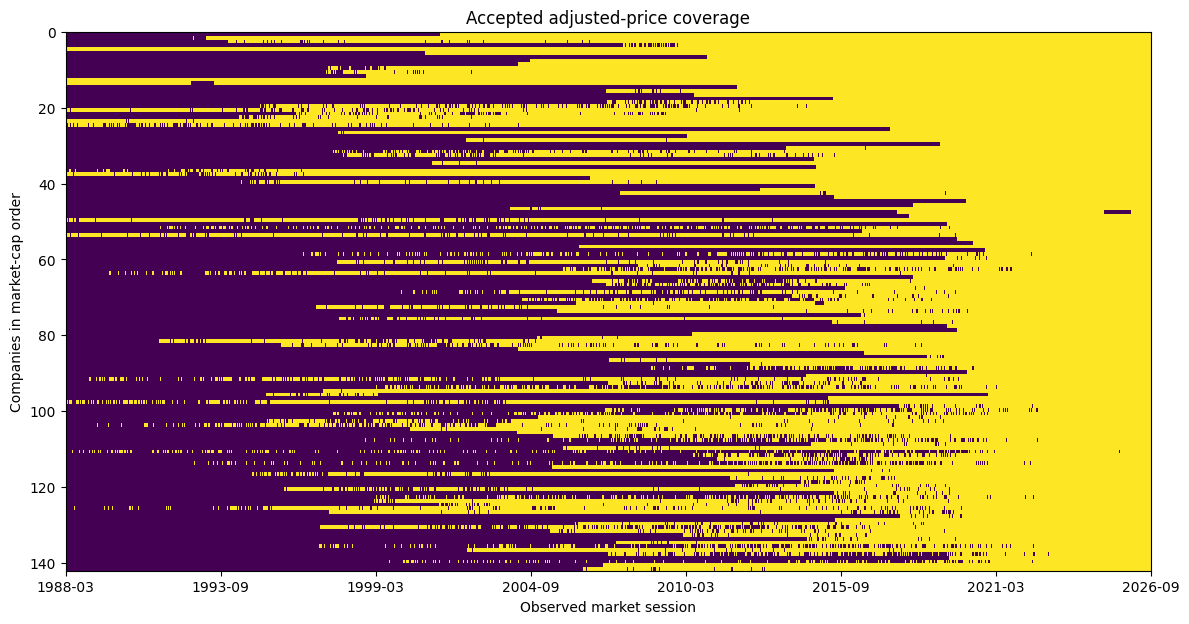

In [3]:
variants = raw.groupby(["CompanyId", "ISIN"]).agg(start=("Date", "min"), end=("Date", "max"),
    security_ids=("SecurityId", lambda x: tuple(sorted(x.dropna().unique()))))
lineage_rows = []
selected = []
for company_id, current in primary.iterrows():
    v = variants.loc[company_id]
    current_isin = current["ISIN"]
    accepted = {current_isin: "endpoint primary security"}
    sid = v.loc[current_isin, "security_ids"]
    candidates = v.loc[v["end"].lt(v.loc[current_isin, "start"])].sort_values("end", ascending=False)
    boundary = v.loc[current_isin, "start"]
    for isin, row in candidates.iterrows():
        if len(sid) == 1 and row["security_ids"] == sid and row["end"] < boundary:
            accepted[isin] = "same CompanyId and stable SecurityId; nonoverlapping"
            boundary = row["start"]
    if company_id == 2331:
        assert v.loc["NO0003043309", "end"] < v.loc["NO0013536151", "start"]
        accepted["NO0003043309"] = "documented Kongsberg 2025 split"
    for isin, row in v.iterrows():
        lineage_rows.append(dict(CompanyId=company_id, ISIN=isin, start=row["start"], end=row["end"],
            security_ids=row["security_ids"], accepted=isin in accepted,
            evidence=accepted.get(isin, "unresolved or overlapping variant; not joined")))
    selected.append(clean.loc[clean["CompanyId"].eq(company_id) & clean["ISIN"].isin(accepted)])
lineage = pd.DataFrame(lineage_rows)
selected_prices = pd.concat(selected, ignore_index=True)
assert not selected_prices.duplicated(["CompanyId", "Date"]).any()
display(lineage)
print("Variants excluded from the primary analytical series:")
display(lineage.loc[~lineage["accepted"]])
# A data-derived observed-session calendar across the complete Oslo export.
sessions = pd.DatetimeIndex(sorted(data.loc[data["Open"].gt(0) & data["Volume"].gt(0), "Date"].unique()))
prices = selected_prices.pivot(index="Date", columns="CompanyId", values="price").reindex(sessions)
prices = prices.reindex(columns=primary.index)
print(f"Observed market sessions: {len(sessions):,}. This is not an official exchange calendar.")
# Keep gaps before differencing: no returns bridging missing market sessions.
returns = np.log(prices).diff()
coverage["analysis_start"] = prices.apply(lambda x: x.first_valid_index())
coverage["analysis_end"] = prices.apply(lambda x: x.last_valid_index())
coverage["valid_prices"] = prices.count()
coverage["return_observations"] = returns.count()
coverage["zero_return_fraction"] = returns.eq(0).sum().div(returns.count())
coverage["repeated_price_pairs"] = (prices.eq(prices.shift()) & prices.notna()).sum()
coverage["missing_sessions_inside_span"] = prices.apply(lambda x: x.loc[x.first_valid_index():x.last_valid_index()].isna().sum())
display(coverage.join(primary[["Name", "market_cap"]]).sort_values("market_cap", ascending=False))
detail_ids = list(primary.head(5).index) if DETAIL_COMPANY_IDS is None else DETAIL_COMPANY_IDS
assert set(detail_ids).issubset(prices.columns)
labels = primary["Name"].to_dict()
fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(prices.notna().T, aspect="auto", interpolation="nearest", extent=[0, len(prices), len(primary), 0])
positions = np.linspace(0, len(prices)-1, 8).astype(int)
ax.set_xticks(positions, [prices.index[i].strftime("%Y-%m") for i in positions])
ax.set(xlabel="Observed market session", ylabel="Companies in market-cap order", title="Accepted adjusted-price coverage")
plt.show()

## 3. Daily log returns and distributions
Daily returns require two consecutive observed market sessions. Genuine zero returns and extreme returns are retained. Normal overlays are descriptive comparisons, not assumptions or formal normality tests. Different stocks can have different sample periods.

,Name,market_cap,Sector,n,mean_daily,std_daily,skewness,excess_kurtosis,zero_return_fraction,q0.01,q0.05,q0.50,q0.95,q0.99,analysis_start,analysis_end
CompanyId,,,,,,,,,,,,,,,,
1309,EQUINOR,9.527135e+11,Energy,6333,0.000478,0.019390,-0.271485,5.089879,0.036318,-0.052068,-0.029310,0.000000,0.031177,0.048505,2001-06-18,2026-09-08
1772,DNB BANK,4.618772e+11,Financials,8414,0.000617,0.021332,0.056100,26.334898,0.060257,-0.057146,-0.029122,0.000000,0.030000,0.059226,1992-09-04,2026-09-08
2331,KONGSBERG GRUPPEN,2.649383e+11,Industrials,7772,0.000922,0.020154,-0.054830,6.322818,0.136773,-0.052747,-0.029898,0.000000,0.033152,0.055651,1993-12-13,2026-09-08
8376,AKER BP,2.278440e+11,Energy,4328,0.000914,0.030205,1.171615,32.582164,0.029806,-0.067620,-0.039574,0.000000,0.041199,0.082380,2007-12-17,2026-09-08
1114,NORSK HYDRO,1.859780e+11,Basic Materials,9659,0.000438,0.020561,-0.049317,5.715965,0.035718,-0.055170,-0.030315,0.000000,0.032121,0.054075,1988-03-14,2026-09-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8353,ROMREAL,1.150024e+08,Real Estate,2524,-0.000373,0.078434,0.093432,17.115287,0.204041,-0.203341,-0.116529,0.000000,0.121810,0.199202,2007-06-11,2026-09-08
12720,2020 BULKERS,9.057708e+07,Industrials,1790,0.003081,0.101711,35.613739,1422.229773,0.039106,-0.077436,-0.042069,0.000000,0.042992,0.079801,2019-07-15,2026-09-08
6171,HØLAND OG SETSKOG,8.764534e+07,Financials,1810,0.001006,0.030639,0.287134,5.588553,0.319890,-0.086165,-0.047434,0.000000,0.050251,0.093862,1999-08-17,2026-09-08


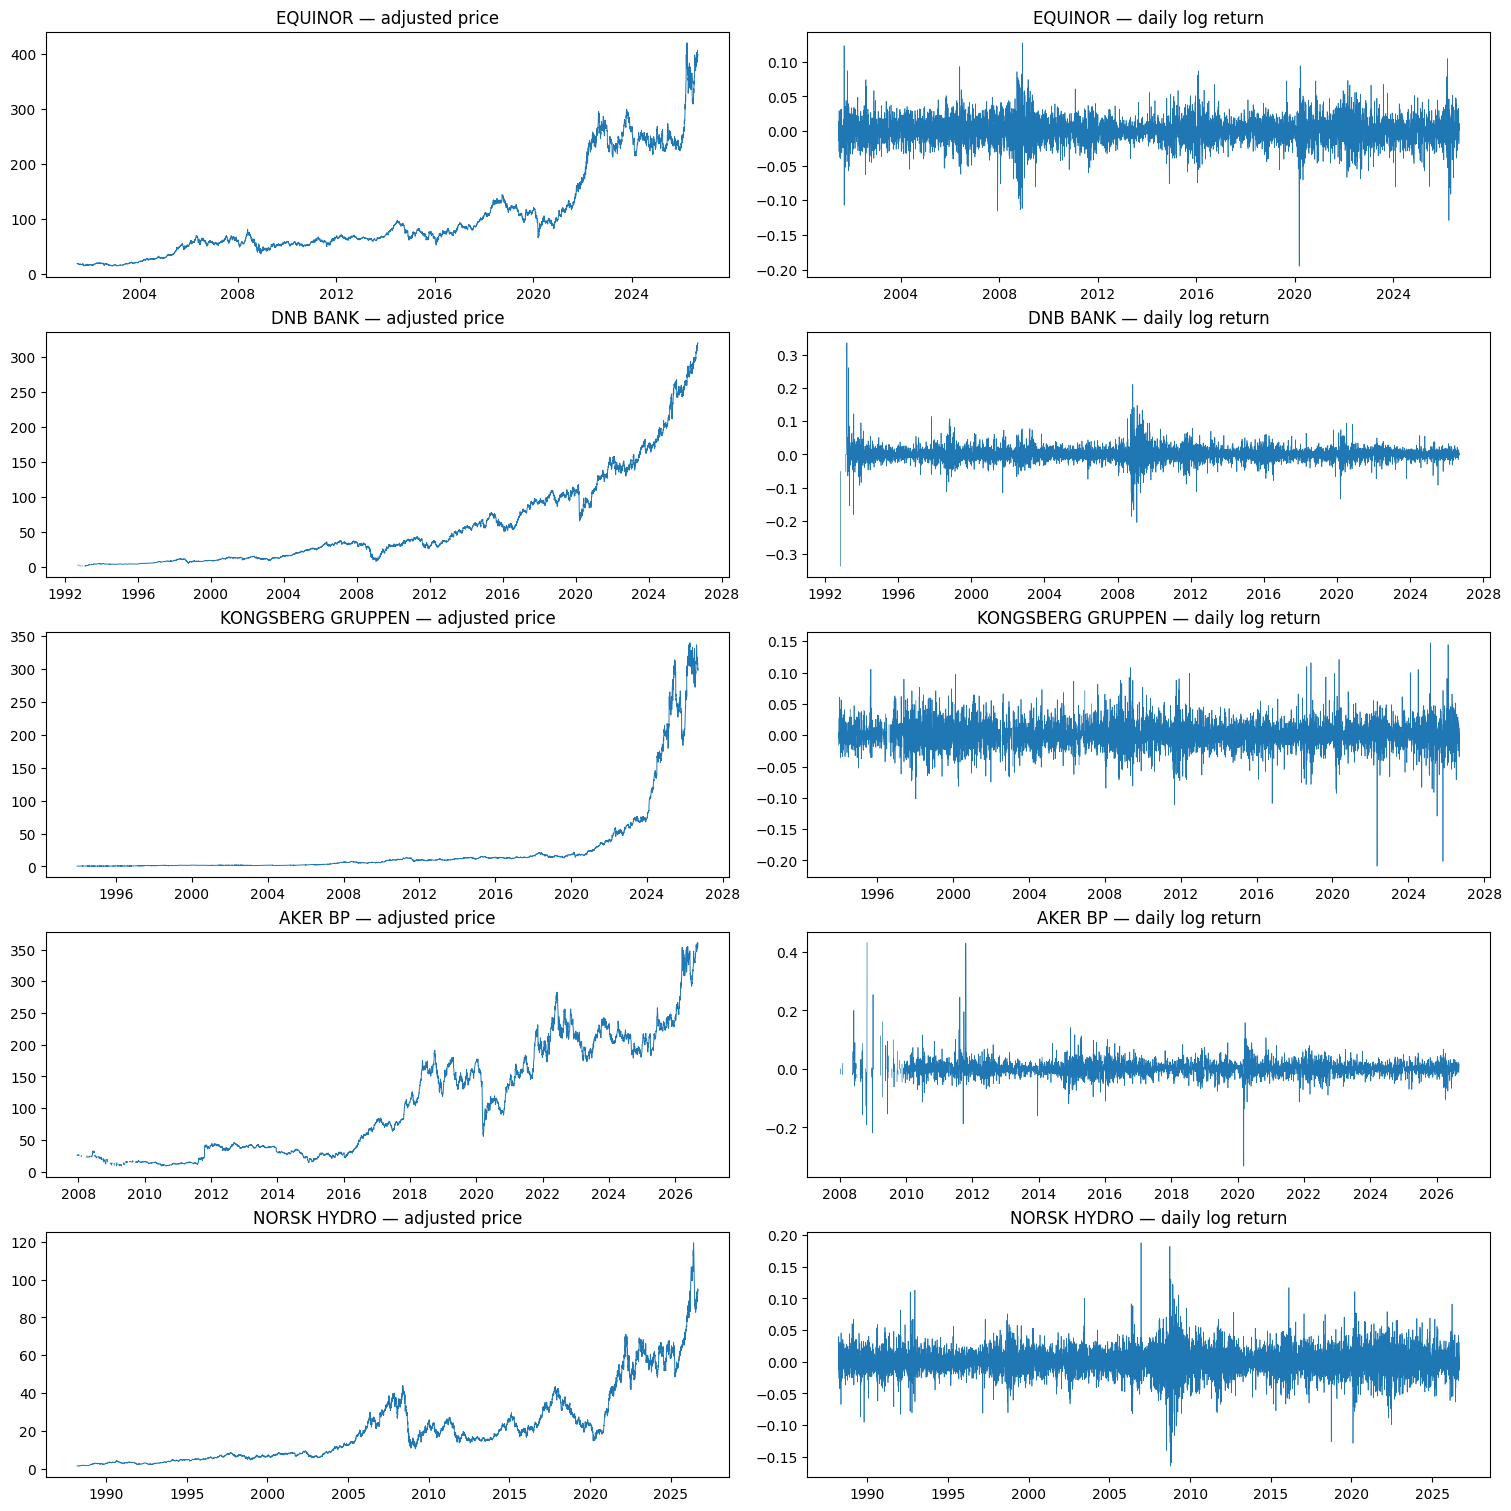

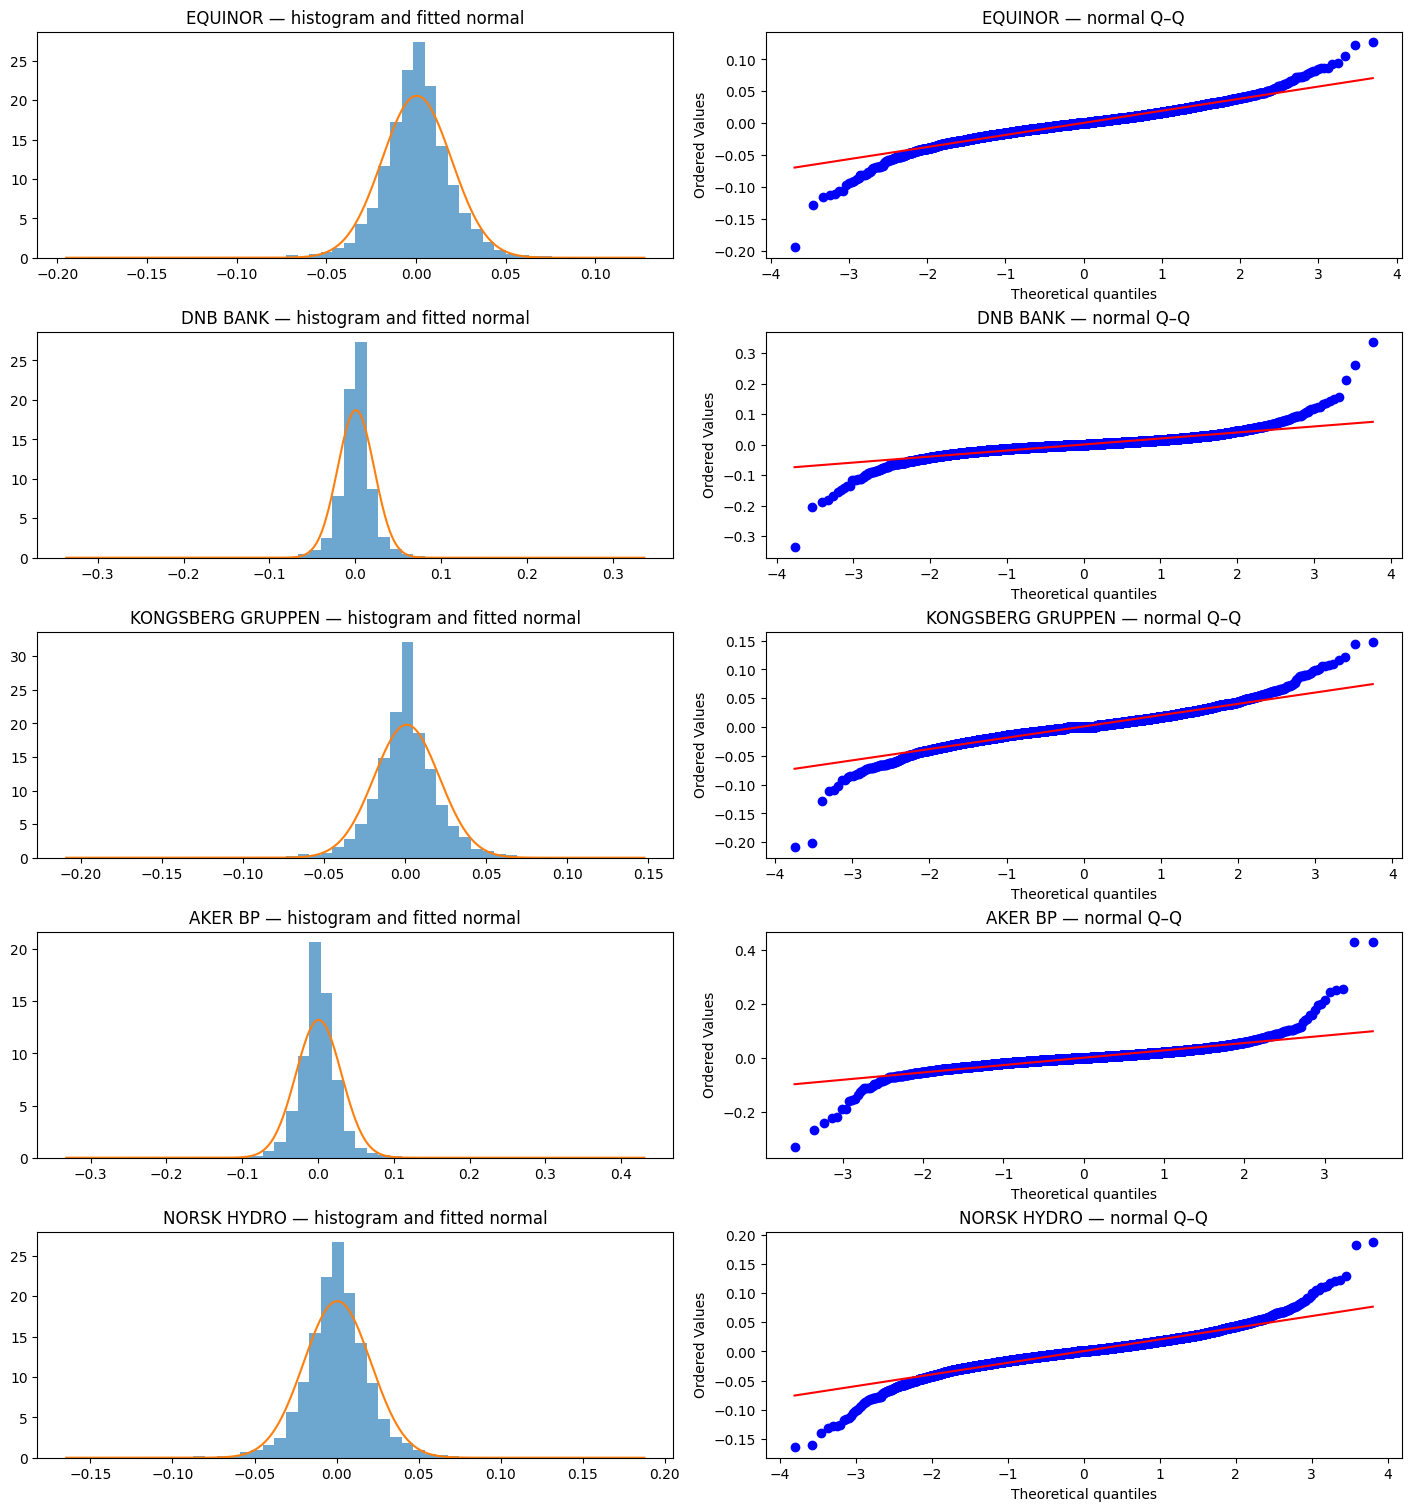

Largest absolute returns: inspection flags, not deletions


,Date,CompanyId,log_return,absolute_return
631324,2026-04-29,12720,4.063616,4.063616
435556,2020-10-21,6066,-3.871201,3.871201
516401,2023-01-30,8360,3.592506,3.592506
445444,2021-02-03,2518,2.341411,2.341411
456009,2021-05-27,7956,-2.337565,2.337565
326115,2017-03-01,7928,-1.961659,1.961659
169816,2009-11-23,7963,-1.819509,1.819509
614885,2025-11-06,8264,-1.490654,1.490654
265730,2014-10-01,8416,-1.438222,1.438222
578288,2024-10-24,12499,1.378326,1.378326


In [4]:
summary = pd.DataFrame({"n": returns.count(), "mean_daily": returns.mean(),
    "std_daily": returns.std(ddof=1), "skewness": returns.skew(), "excess_kurtosis": returns.kurt(),
    "zero_return_fraction": coverage["zero_return_fraction"]})
for q in [0.01, 0.05, 0.50, 0.95, 0.99]:
    summary[f"q{q:.2f}"] = returns.quantile(q)
summary = primary[["Name", "market_cap", "Sector"]].join(summary).join(coverage[["analysis_start", "analysis_end"]])
display(summary)
fig, axes = plt.subplots(len(detail_ids), 2, figsize=(15, 3*len(detail_ids)), squeeze=False, constrained_layout=True)
for row, cid in enumerate(detail_ids):
    axes[row, 0].plot(prices.index, prices[cid], linewidth=0.7)
    axes[row, 0].set_title(f"{labels[cid]} — adjusted price")
    axes[row, 1].plot(returns.index, returns[cid], linewidth=0.5)
    axes[row, 1].set_title(f"{labels[cid]} — daily log return")
plt.show()
fig, axes = plt.subplots(len(detail_ids), 2, figsize=(14, 3*len(detail_ids)), squeeze=False, constrained_layout=True)
for row, cid in enumerate(detail_ids):
    values = returns[cid].dropna()
    if len(values) < 2 or values.std() == 0:
        continue
    axes[row, 0].hist(values, bins=50, density=True, alpha=0.65)
    x = np.linspace(values.min(), values.max(), 400)
    axes[row, 0].plot(x, stats.norm.pdf(x, values.mean(), values.std(ddof=1)))
    axes[row, 0].set_title(f"{labels[cid]} — histogram and fitted normal")
    stats.probplot(values, dist="norm", plot=axes[row, 1])
    axes[row, 1].set_title(f"{labels[cid]} — normal Q–Q")
plt.show()
extremes = returns.stack().rename("log_return").reset_index().rename(columns={"level_0": "Date"})
extremes["absolute_return"] = extremes["log_return"].abs()
print("Largest absolute returns: inspection flags, not deletions")
display(extremes.nlargest(20, "absolute_return"))

## 4. Rolling volatility and observed drawdowns
Annualised volatility uses daily sample standard deviation × √252. Rolling estimates require all 60 session returns. Drawdowns compare adjusted prices with the largest previously observed adjusted price; gaps remain visible. Annualisation is a convention, not a forecast.

,Name,n,annualised_volatility,maximum_drawdown
CompanyId,,,,
1309,EQUINOR,6333,0.307814,-0.549743
1772,DNB BANK,8414,0.338628,-0.803990
2331,KONGSBERG GRUPPEN,7772,0.319937,-0.418937
8376,AKER BP,4328,0.479483,-0.732857
1114,NORSK HYDRO,9659,0.326395,-0.761682
...,...,...,...,...
8353,ROMREAL,2524,1.245101,-0.997925
12720,2020 BULKERS,1790,1.614613,-0.635417
6171,HØLAND OG SETSKOG,1810,0.486373,-0.444203


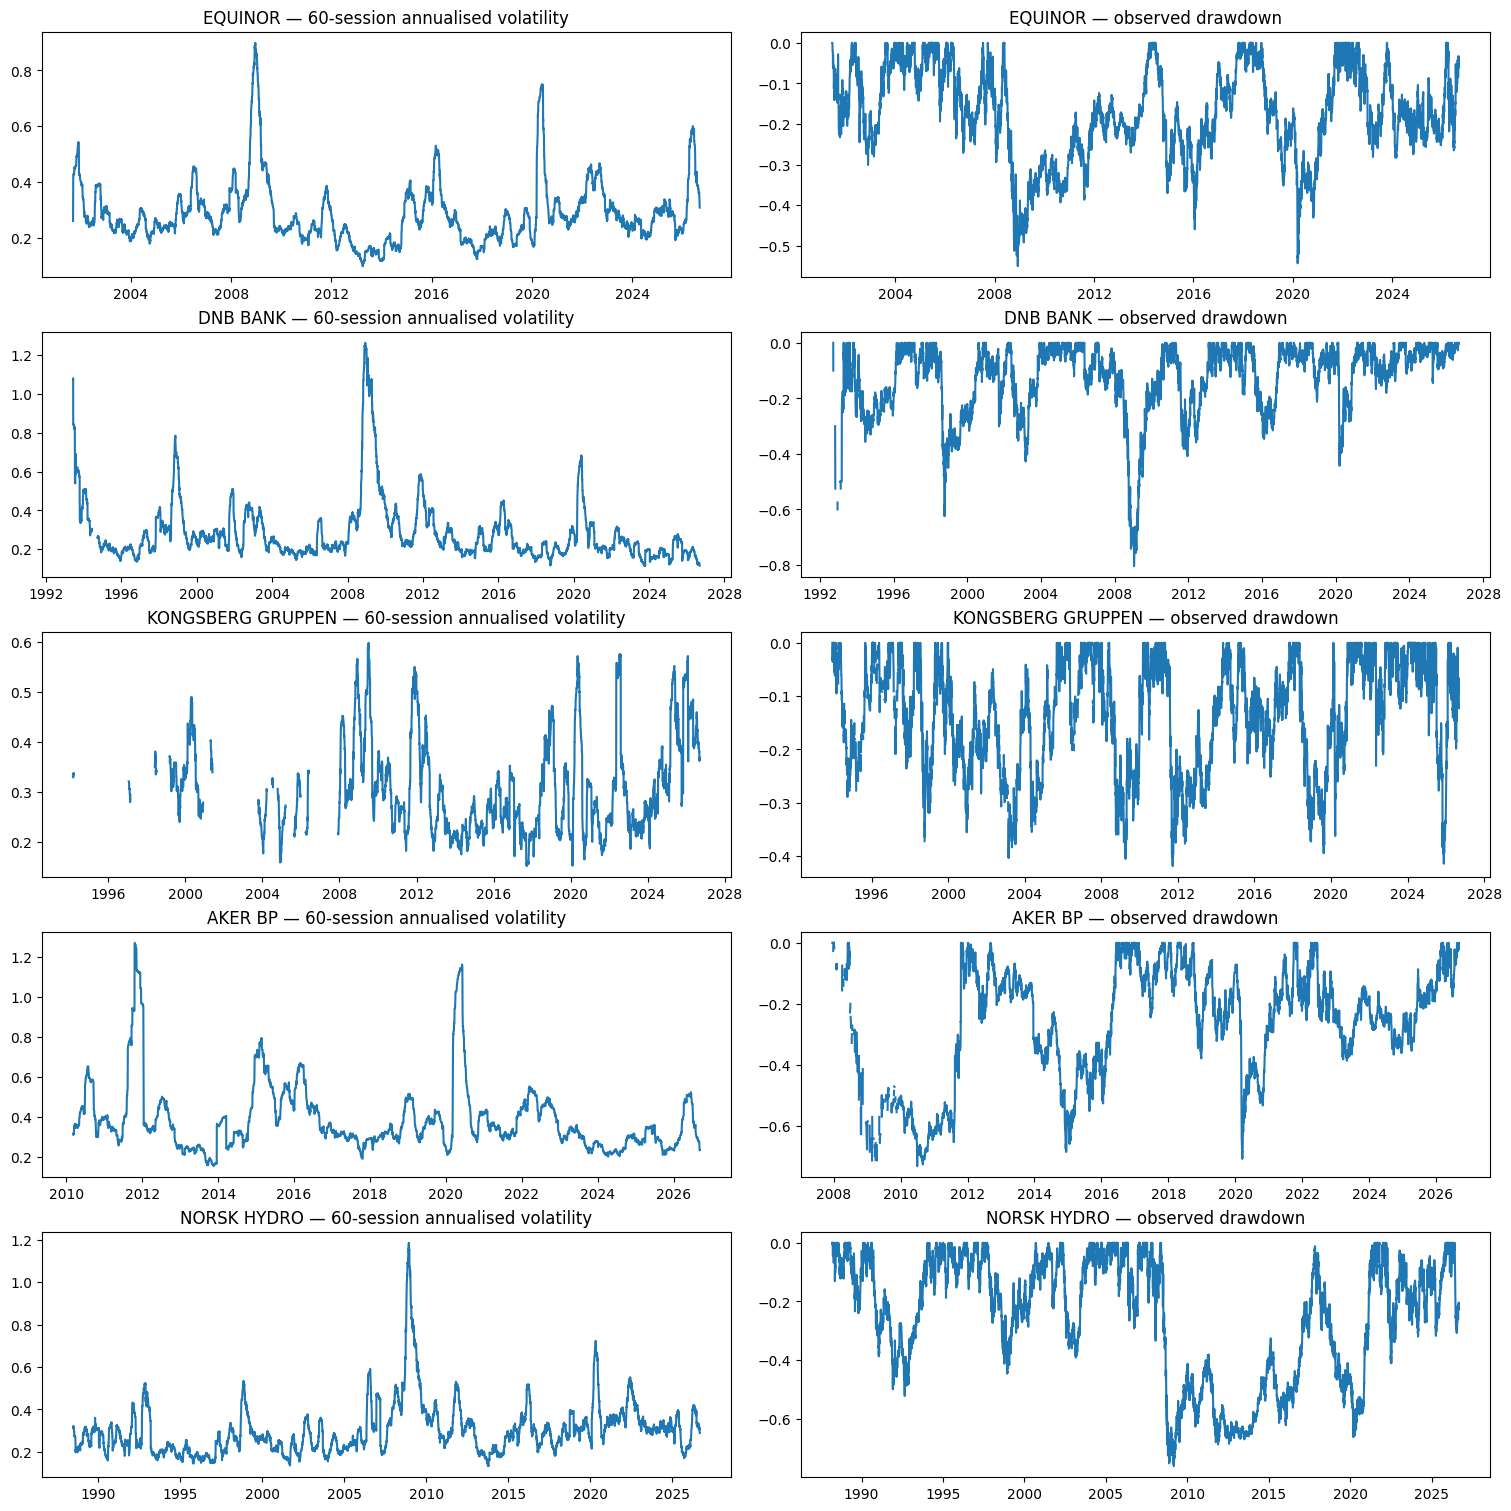

In [5]:
rolling_volatility = returns.rolling(ROLLING, min_periods=ROLLING).std(ddof=1) * np.sqrt(252)
drawdowns = prices.div(prices.cummax()).sub(1)
summary["annualised_volatility"] = returns.std(ddof=1) * np.sqrt(252)
summary["maximum_drawdown"] = drawdowns.min()
display(summary[["Name", "n", "annualised_volatility", "maximum_drawdown"]])
fig, axes = plt.subplots(len(detail_ids), 2, figsize=(15, 3*len(detail_ids)), squeeze=False, constrained_layout=True)
for row, cid in enumerate(detail_ids):
    axes[row, 0].plot(rolling_volatility.index, rolling_volatility[cid])
    axes[row, 0].set_title(f"{labels[cid]} — 60-session annualised volatility")
    axes[row, 1].plot(drawdowns.index, drawdowns[cid])
    axes[row, 1].set_title(f"{labels[cid]} — observed drawdown")
plt.show()

## 5. Pairwise dependence and joint extreme losses
Each pair uses its maximum overlapping daily-return observations. Correlations require 252 paired observations. Periods differ between pairs: the resulting matrices are descriptive and need not be positive semidefinite, so they cannot be used directly as fitted copula correlation matrices.

Lower-tail events use average-rank pseudo-observations `rank / (n + 1) ≤ 0.05`, calculated within the pair-aligned sample. Ties can change the observed marginal event frequencies. Tail estimates require 1,000 pairs and each conditional probability requires 20 conditioning events. These are finite-threshold co-loss measures, not evidence of asymptotic tail dependence.

In [6]:
def pair_metrics(x, y):
    """Calculate aligned, descriptive dependence with explicit sample-size rules."""
    aligned = pd.concat([x, y], axis=1).dropna()
    n_pair = len(aligned)
    result = dict(n_pair=n_pair, first_date=aligned.index.min(), last_date=aligned.index.max(),
                  pearson=np.nan, spearman=np.nan, tail_n_i=np.nan, tail_n_j=np.nan,
                  joint_tail_count=np.nan, joint_probability=np.nan, independence_reference=np.nan,
                  conditional_i_given_j=np.nan, conditional_j_given_i=np.nan,
                  correlation_status="insufficient overlap", tail_status="insufficient overlap")
    if n_pair < 2:
        return result
    if aligned.nunique().lt(2).any():
        result.update(correlation_status="constant series", tail_status="constant series")
        return result
    if n_pair >= MIN_CORRELATION:
        result.update(pearson=aligned.iloc[:, 0].corr(aligned.iloc[:, 1]),
                      spearman=stats.spearmanr(aligned.iloc[:, 0], aligned.iloc[:, 1]).statistic,
                      correlation_status="available")
    if n_pair >= MIN_TAIL:
        tail = aligned.rank(method="average").div(n_pair + 1).le(TAIL_LEVEL)
        a, b = tail.sum().to_numpy()
        joint = int(tail.all(axis=1).sum())
        result.update(tail_n_i=int(a), tail_n_j=int(b), joint_tail_count=joint,
                      joint_probability=joint/n_pair, independence_reference=(a/n_pair)*(b/n_pair),
                      conditional_i_given_j=joint/b if b >= MIN_TAIL_EVENTS else np.nan,
                      conditional_j_given_i=joint/a if a >= MIN_TAIL_EVENTS else np.nan,
                      tail_status="available" if min(a, b) >= MIN_TAIL_EVENTS else "too few conditioning events")
    return result

pair_rows = []
for i, j in combinations(primary.index, 2):
    pair_rows.append(dict(company_i=i, company_j=j, sector_i=primary.loc[i, "Sector"],
                          sector_j=primary.loc[j, "Sector"], **pair_metrics(returns[i], returns[j])))
pairs = pd.DataFrame(pair_rows)
pairs["same_sector"] = pairs["sector_i"].eq(pairs["sector_j"])
display(pairs)
display(pairs.groupby(["correlation_status", "tail_status"]).size().rename("pairs").to_frame())
print("Strongest positive / negative correlations (periods differ):")
display(pd.concat([pairs.nlargest(10, "pearson"), pairs.nsmallest(10, "pearson")]))
display(pairs.loc[pairs["same_sector"]].groupby("sector_i").agg(
    pairs=("n_pair", "size"), available=("pearson", "count"), median_overlap=("n_pair", "median"),
    median_pearson=("pearson", "median"), median_spearman=("spearman", "median")))

,company_i,company_j,sector_i,sector_j,n_pair,first_date,last_date,pearson,spearman,tail_n_i,tail_n_j,joint_tail_count,joint_probability,independence_reference,conditional_i_given_j,conditional_j_given_i,correlation_status,tail_status,same_sector
0,1309,1772,Energy,Financials,6333,2001-06-19,2026-09-08,0.390810,0.353880,316,316,94,0.014843,0.002490,0.297468,0.297468,available,available,False
1,1309,2331,Energy,Industrials,6136,2001-06-19,2026-09-08,0.226596,0.210200,306,306,63,0.010267,0.002487,0.205882,0.205882,available,available,False
2,1309,8376,Energy,Energy,4328,2007-12-18,2026-09-08,0.543913,0.600609,216,216,93,0.021488,0.002491,0.430556,0.430556,available,available,True
3,1309,1114,Energy,Basic Materials,6333,2001-06-19,2026-09-08,0.530297,0.495785,316,316,121,0.019106,0.002490,0.382911,0.382911,available,available,False
4,1309,6233,Energy,Telecommunications,6333,2001-06-19,2026-09-08,0.303463,0.293888,316,316,76,0.012001,0.002490,0.240506,0.240506,available,available,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10006,12720,8264,Industrials,Energy,1790,2019-07-16,2026-09-08,0.015733,0.105343,89,89,11,0.006145,0.002472,0.123596,0.123596,available,available,False
10007,12720,8135,Industrials,Energy,1790,2019-07-16,2026-09-08,0.038398,0.116634,89,89,9,0.005028,0.002472,0.101124,0.101124,available,available,False
10008,6171,8264,Financials,Energy,1717,2007-04-02,2026-09-08,0.005338,0.006852,85,85,5,0.002912,0.002451,0.058824,0.058824,available,available,False
10009,6171,8135,Financials,Energy,1724,2006-10-24,2026-09-08,0.001059,-0.030991,86,86,8,0.004640,0.002488,0.093023,0.093023,available,available,False


,,pairs
correlation_status,tail_status,
available,available,10011


Strongest positive / negative correlations (periods differ):


,company_i,company_j,sector_i,sector_j,n_pair,first_date,last_date,pearson,spearman,tail_n_i,tail_n_j,joint_tail_count,joint_probability,independence_reference,conditional_i_given_j,conditional_j_given_i,correlation_status,tail_status,same_sector
5292,12748,8624,Energy,Energy,1645,2020-02-20,2026-09-08,0.678867,0.602815,82,82,39,0.023708,0.002485,0.475610,0.475610,available,available,True
1513,6117,12643,Industrials,Industrials,1875,2019-03-11,2026-09-08,0.665998,0.657615,93,93,48,0.025600,0.002460,0.516129,0.516129,available,available,True
1890,1797,1695,Financials,Financials,3682,2012-01-03,2026-09-08,0.665236,0.617196,184,184,89,0.024172,0.002497,0.483696,0.483696,available,available,True
460,8376,12748,Energy,Energy,1645,2020-02-20,2026-09-08,0.648437,0.577303,82,82,37,0.022492,0.002485,0.451220,0.451220,available,available,True
4557,1015,12748,Energy,Energy,1645,2020-02-20,2026-09-08,0.636259,0.596951,82,82,38,0.023100,0.002485,0.463415,0.463415,available,available,True
5269,12748,8108,Energy,Energy,1645,2020-02-20,2026-09-08,0.620183,0.560124,82,82,36,0.021884,0.002485,0.439024,0.439024,available,available,True
153,1772,1797,Financials,Financials,3682,2012-01-03,2026-09-08,0.597745,0.539124,184,184,79,0.021456,0.002497,0.429348,0.429348,available,available,True
3579,7148,8163,Consumer Staples,Consumer Staples,4964,2006-10-12,2026-09-08,0.578030,0.597510,248,248,105,0.021152,0.002496,0.423387,0.423387,available,available,True
1907,1797,1972,Financials,Financials,3674,2012-01-03,2026-09-08,0.577597,0.516444,183,183,79,0.021502,0.002481,0.431694,0.431694,available,available,True
1387,6030,12353,Energy,Energy,2996,2014-09-30,2026-09-08,0.575098,0.612389,149,149,62,0.020694,0.002473,0.416107,0.416107,available,available,True


,pairs,available,median_overlap,median_pearson,median_spearman
sector_i,,,,,
Basic Materials,15,15,2120.0,0.208743,0.230168
Consumer Discretionary,36,36,1725.0,0.039526,0.041375
Consumer Staples,28,28,4626.5,0.305151,0.413667
Energy,528,528,3749.0,0.126961,0.159431
Financials,406,406,2518.5,0.116664,0.089967
Health Care,21,21,2766.0,0.063414,0.065941
Industrials,406,406,2737.0,0.091964,0.099651
Real Estate,3,3,1744.0,0.043551,0.044122
Technology,91,91,2126.0,0.093869,0.089358


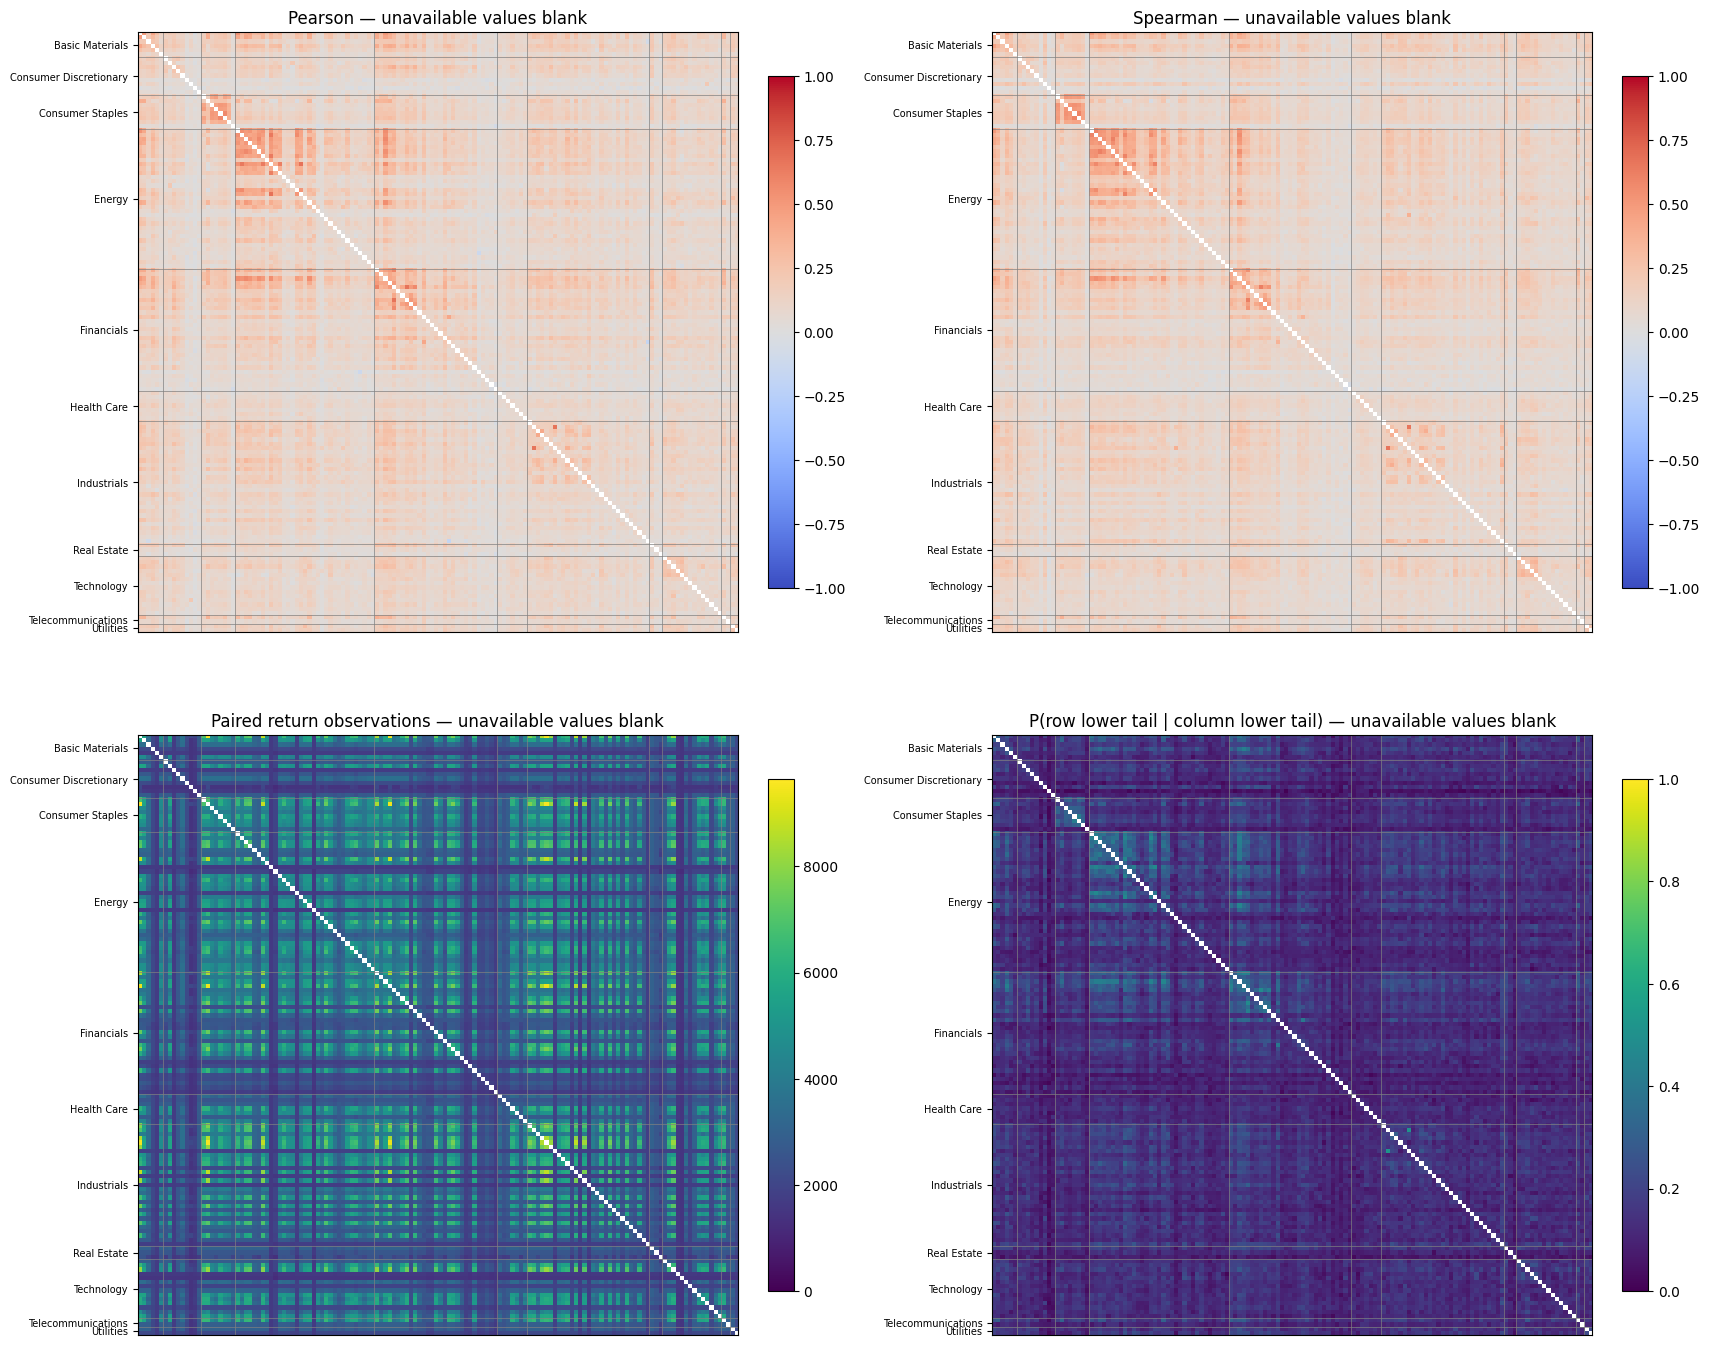

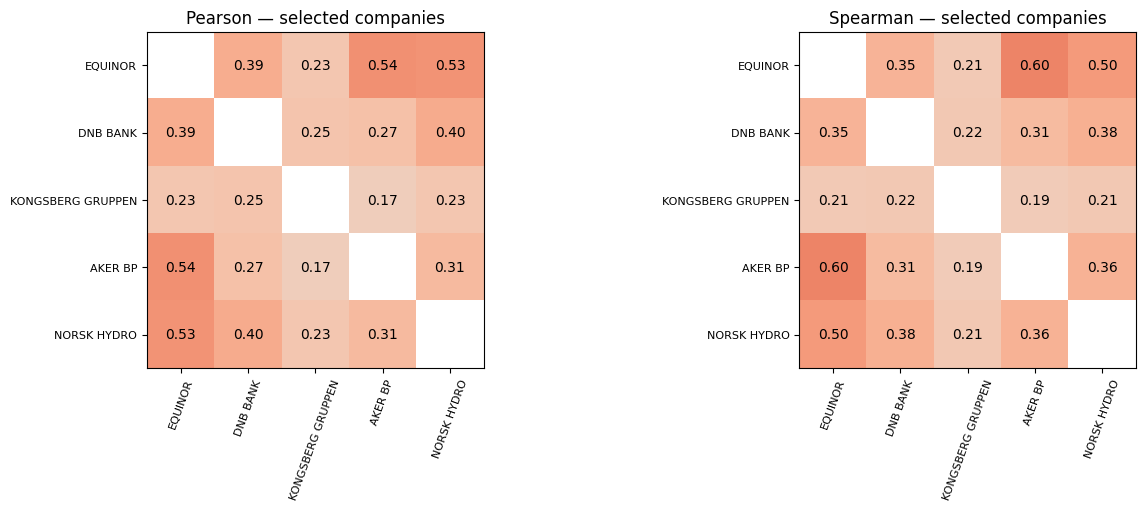

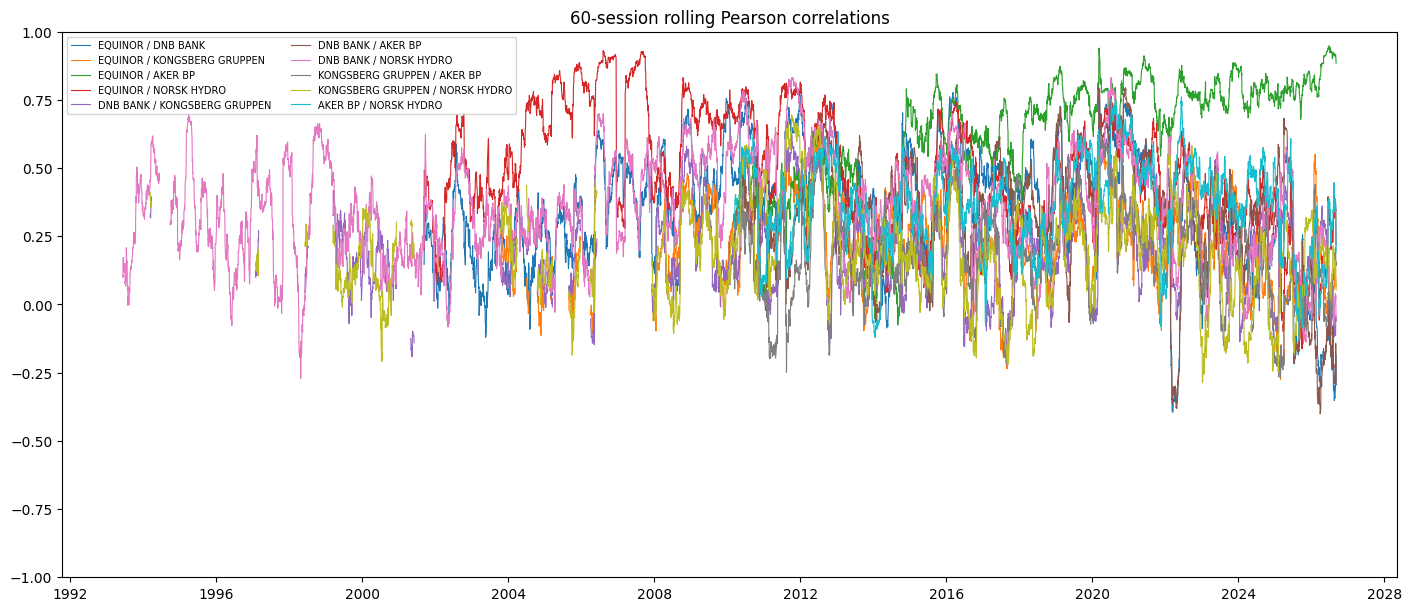

,company_i,company_j,n_pair,first_date,last_date,tail_n_i,tail_n_j,joint_tail_count,joint_probability,independence_reference,conditional_i_given_j,conditional_j_given_i,tail_status
0,1309,1772,6333,2001-06-19,2026-09-08,316,316,94,0.014843,0.002490,0.297468,0.297468,available
1,1309,2331,6136,2001-06-19,2026-09-08,306,306,63,0.010267,0.002487,0.205882,0.205882,available
2,1309,8376,4328,2007-12-18,2026-09-08,216,216,93,0.021488,0.002491,0.430556,0.430556,available
3,1309,1114,6333,2001-06-19,2026-09-08,316,316,121,0.019106,0.002490,0.382911,0.382911,available
141,1772,2331,7769,1993-12-14,2026-09-08,388,388,94,0.012099,0.002494,0.242268,0.242268,available
142,1772,8376,4328,2007-12-18,2026-09-08,216,216,61,0.014094,0.002491,0.282407,0.282407,available
143,1772,1114,8414,1992-09-24,2026-09-08,420,420,136,0.016164,0.002492,0.323810,0.323810,available
281,2331,8376,4328,2007-12-18,2026-09-08,216,216,42,0.009704,0.002491,0.194444,0.194444,available
282,2331,1114,7772,1993-12-14,2026-09-08,388,388,90,0.011580,0.002492,0.231959,0.231959,available
420,8376,1114,4328,2007-12-18,2026-09-08,216,216,59,0.013632,0.002491,0.273148,0.273148,available


In [7]:
def pair_matrix(metric, directional=False):
    matrix = pd.DataFrame(np.nan, index=primary.index, columns=primary.index)
    for row in pairs.itertuples():
        matrix.loc[row.company_i, row.company_j] = getattr(row, metric)
        reverse = row.conditional_j_given_i if directional else getattr(row, metric)
        matrix.loc[row.company_j, row.company_i] = reverse
    return matrix

order = primary.assign(sector_sort=primary["Sector"].fillna("Unknown")).sort_values(
    ["sector_sort", "market_cap"], ascending=[True, False]).index
sector_order = primary.loc[order, "Sector"].fillna("Unknown")
boundaries = np.flatnonzero(sector_order.to_numpy()[1:] != sector_order.to_numpy()[:-1]) + 1
starts = np.r_[0, boundaries]
ends = np.r_[boundaries, len(order)]
fig, axes = plt.subplots(2, 2, figsize=(17, 14), constrained_layout=True)
for ax, metric, title, low, high in zip(axes.flat,
        ["pearson", "spearman", "n_pair", "conditional_i_given_j"],
        ["Pearson", "Spearman", "Paired return observations", "P(row lower tail | column lower tail)"],
        [-1, -1, 0, 0], [1, 1, None, 1]):
    matrix = pair_matrix(metric, directional=metric.startswith("conditional"))
    im = ax.imshow(matrix.loc[order, order], vmin=low, vmax=high,
                   cmap="coolwarm" if metric in ["pearson", "spearman"] else "viridis")
    ax.set_title(title + " — unavailable values blank")
    for boundary in boundaries:
        ax.axhline(boundary - 0.5, color="grey", linewidth=0.5)
        ax.axvline(boundary - 0.5, color="grey", linewidth=0.5)
    ax.set_yticks((starts + ends - 1)/2, sector_order.iloc[starts].tolist(), fontsize=7)
    ax.set_xticks([])
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, metric in zip(axes, ["pearson", "spearman"]):
    m = pair_matrix(metric).loc[detail_ids, detail_ids]
    im = ax.imshow(m, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(detail_ids)), [labels[i] for i in detail_ids], rotation=70, fontsize=8)
    ax.set_yticks(range(len(detail_ids)), [labels[i] for i in detail_ids], fontsize=8)
    for a in range(len(detail_ids)):
        for b in range(len(detail_ids)):
            if pd.notna(m.iloc[a, b]): ax.text(b, a, f"{m.iloc[a,b]:.2f}", ha="center", va="center")
    ax.set_title(metric.capitalize() + " — selected companies")
plt.show()
fig, ax = plt.subplots(figsize=(14, 6), constrained_layout=True)
for i, j in combinations(detail_ids, 2):
    rolling = returns[i].rolling(ROLLING, min_periods=ROLLING).corr(returns[j])
    # Count paired observations explicitly: do not bridge incomplete windows.
    valid_window = (returns[i].notna() & returns[j].notna()).rolling(ROLLING).sum().eq(ROLLING)
    ax.plot(rolling.index, rolling.where(valid_window), linewidth=0.8, label=f"{labels[i]} / {labels[j]}")
ax.set(title="60-session rolling Pearson correlations", ylim=(-1, 1))
ax.legend(fontsize=7, ncol=2)
plt.show()
display(pairs.loc[pairs["company_i"].isin(detail_ids) & pairs["company_j"].isin(detail_ids),
    ["company_i", "company_j", "n_pair", "first_date", "last_date", "tail_n_i", "tail_n_j",
     "joint_tail_count", "joint_probability", "independence_reference", "conditional_i_given_j", "conditional_j_given_i", "tail_status"]])

## 6. Validation
These checks cover the actual dataset and small hand-calculated examples. They test missing-session behaviour, supported ISIN transitions, sample thresholds, ties, constant series, and probability bounds.

In [8]:
assert len(primary) == 142
assert len(pairs) == 10011
assert primary.index[2] == 2331
assert not selected_prices.duplicated(["CompanyId", "Date"]).any()
assert lineage.loc[lineage["CompanyId"].eq(2331) & lineage["accepted"], "ISIN"].nunique() == 2
assert set(["NO0010031479", "NO0010161896"]).issubset(
    set(lineage.loc[lineage["CompanyId"].eq(1772) & lineage["accepted"], "ISIN"]))
assert prices.loc[pd.Timestamp("2025-05-30"), 2331] == data.loc[
    data["ISIN"].eq("NO0003043309") & data["Date"].eq("2025-05-30"), "AdjustedPrice"].iloc[0]
for cid, date in [(2331, "2025-06-03"), (1772, "2021-07-02")]:
    assert pd.notna(returns.loc[date, cid])
    assert np.isclose(returns.loc[date, cid], np.log(prices[cid]).diff().loc[date])
example = pd.Series([100., 110., np.nan, 121., 110.])
r = np.log(example).diff()
assert np.isclose(r.iloc[1], np.log(1.1)) and pd.isna(r.iloc[3])
assert np.isclose((example/example.cummax()-1).iloc[-1], 110/121-1)
assert np.isclose(pd.Series([0., 1., 2.]).rolling(3).std().iloc[-1], 1)
assert pd.Series([0., 1., np.nan, 2.]).rolling(3).std().isna().all()
x = pd.Series(np.arange(1000, dtype=float))
t = pair_metrics(x, x)
assert t["joint_tail_count"] == 50 and t["conditional_i_given_j"] == 1
assert t["joint_probability"] == 0.05 and np.isclose(t["independence_reference"], 0.0025)
assert np.isclose(pair_metrics(x, -x)["pearson"], -1)
assert pd.isna(pair_metrics(x.iloc[:251], x.iloc[:251])["pearson"])
assert pd.isna(pair_metrics(x.iloc[:999], x.iloc[:999])["joint_probability"])
assert pair_metrics(pd.Series(np.ones(1000)), x)["correlation_status"] == "constant series"
tied = pd.Series(np.repeat(np.arange(100), 10))
assert pair_metrics(tied, tied)["conditional_i_given_j"] == 1
for metric in ["pearson", "spearman"]:
    m = pair_matrix(metric)
    assert np.allclose(m, m.T, equal_nan=True)
    assert pairs[metric].dropna().between(-1.000001, 1.000001).all()
for metric in ["joint_probability", "conditional_i_given_j", "conditional_j_given_i"]:
    assert pairs[metric].dropna().between(0, 1).all()
assert returns.where(prices.isna() | prices.shift().isna()).isna().all().all()
print("All dataset and hand-calculated checks passed.")

All dataset and hand-calculated checks passed.


## Findings and interpretation
The following compact summary is computed from the results, rather than prewritten conclusions. Correlations and tail estimates use different pairwise periods; rankings are exploratory and are not causal findings. Missing CompanyIds, unresolved security histories, stale prices and endpoint survivorship limit generalisation. No copula model is fitted here.

### Variables in the final tables
The first table shows the five selected companies. `CompanyId` (the row index) is the source identifier; `Name` is the name of the selected current security. `n` is the number of observed daily log returns. `std_daily` is their sample standard deviation; `skewness` describes asymmetry; and `excess_kurtosis` describes tail heaviness relative to a normal distribution (whose excess kurtosis is zero). `annualised_volatility` is `std_daily × √252`. `maximum_drawdown` is the largest observed fall from a previous adjusted-price peak. Standard deviations, volatility and drawdown are reported as fractions, so 0.20 means 20%.

The second table shows the ten largest estimated conditional co-loss probabilities. `company_i` and `company_j` are CompanyIds; `n_pair` counts dates with returns for both companies, and `first_date`/`last_date` bound those paired observations. A lower-tail event has average rank divided by `n_pair + 1` at or below 0.05 within the aligned pair. `tail_n_j` counts company j's lower-tail events, and `joint_tail_count` counts days when both companies have one. `conditional_i_given_j = joint_tail_count / tail_n_j` estimates the fraction of company j's lower-tail days on which company i is also in its lower tail. These are sample fractions at a 5% threshold, not asymptotic tail-dependence estimates.

In [9]:
print(f"Analysed {len(primary)} endpoint-selected companies and {len(pairs):,} pairs.")
print(f"Available correlations: {pairs['pearson'].notna().sum():,}; available two-direction tail estimates: {pairs['tail_status'].eq('available').sum():,}.")
print(f"Flagged conflicting security/date groups: {len(conflict_keys)}; excluded ISIN variants: {(~lineage['accepted']).sum()}.")
print("Selected companies: descriptive distribution and risk results")
display(summary.loc[detail_ids, ["Name", "n", "std_daily", "skewness", "excess_kurtosis", "annualised_volatility", "maximum_drawdown"]])
print("Largest finite-threshold conditional co-loss estimates (inspect counts and periods):")
display(pairs.nlargest(10, "conditional_i_given_j")[["company_i", "company_j", "n_pair", "first_date", "last_date", "tail_n_j", "joint_tail_count", "conditional_i_given_j"]])
plt.close("all")

Analysed 142 endpoint-selected companies and 10,011 pairs.
Available correlations: 10,011; available two-direction tail estimates: 10,011.
Flagged conflicting security/date groups: 3; excluded ISIN variants: 29.
Selected companies: descriptive distribution and risk results


,Name,n,std_daily,skewness,excess_kurtosis,annualised_volatility,maximum_drawdown
CompanyId,,,,,,,
1309,EQUINOR,6333,0.019390,-0.271485,5.089879,0.307814,-0.549743
1772,DNB BANK,8414,0.021332,0.056100,26.334898,0.338628,-0.803990
2331,KONGSBERG GRUPPEN,7772,0.020154,-0.054830,6.322818,0.319937,-0.418937
8376,AKER BP,4328,0.030205,1.171615,32.582164,0.479483,-0.732857
1114,NORSK HYDRO,9659,0.020561,-0.049317,5.715965,0.326395,-0.761682


Largest finite-threshold conditional co-loss estimates (inspect counts and periods):


,company_i,company_j,n_pair,first_date,last_date,tail_n_j,joint_tail_count,conditional_i_given_j
1513,6117,12643,1875,2019-03-11,2026-09-08,93,48,0.516129
1890,1797,1695,3682,2012-01-03,2026-09-08,184,89,0.483696
493,8376,12627,1816,2019-06-19,2026-09-08,90,43,0.477778
5292,12748,8624,1645,2020-02-20,2026-09-08,82,39,0.475610
4557,1015,12748,1645,2020-02-20,2026-09-08,82,38,0.463415
1041,6047,7765,5525,2004-09-09,2026-09-08,276,127,0.460145
460,8376,12748,1645,2020-02-20,2026-09-08,82,37,0.451220
152,1772,1955,8337,1993-06-22,2026-09-08,416,185,0.444712
1035,6047,12627,1816,2019-06-19,2026-09-08,90,40,0.444444
5269,12748,8108,1645,2020-02-20,2026-09-08,82,36,0.439024
